# Análise Diagnóstica - Câncer de Mama
Notebook de análise exploratória de dados (EDA) para inspeção, estatísticas e visualizações da base.

## 1. Importação das Bibliotecas e Configuração

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

## 2. Carregamento e Inspeção Inicial da Base

In [2]:
# Suporta execução tanto na raiz do projeto quanto dentro de 'notebook/'
caminho_arquivo = "../data/BreastCancer.csv" if os.path.exists("../data/BreastCancer.csv") else "data/BreastCancer.csv"
df = pd.read_csv(caminho_arquivo)

print("--- 5 PRIMEIRAS LINHAS ---")
display(df.head())

print("\n--- ESTRUTURA E TIPOS DE DADOS ---")
df.info()

print(f"\nDimensão da base: {df.shape[0]} linhas e {df.shape[1]} colunas.")

--- 5 PRIMEIRAS LINHAS ---


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



--- ESTRUTURA E TIPOS DE DADOS ---
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  p

## 3. Verificação de Valores Nulos e Duplicados

In [3]:
print("--- VALORES AUSENTES POR COLUNA ---")
nulos = df.isnull().sum()
print(nulos[nulos > 0] if nulos.sum() > 0 else "Nenhum valor ausente encontrado.")

print(f"\nLinhas duplicadas identificadas: {df.duplicated().sum()}")

--- VALORES AUSENTES POR COLUNA ---
Unnamed: 32    569
dtype: int64

Linhas duplicadas identificadas: 0


## 4. Estatísticas Descritivas

In [4]:
print("--- ESTATÍSTICAS DESCRITIVAS DAS VARIÁVEIS NUMÉRICAS ---")
display(df.describe().T)

--- ESTATÍSTICAS DESCRITIVAS DAS VARIÁVEIS NUMÉRICAS ---


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


## 5. Identificação e Análise da Variável Alvo (Target)

--- DISTRIBUIÇÃO DA VARIÁVEL ALVO: 'diagnosis' ---
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


C:\Users\Bruno\AppData\Local\Temp\ipykernel_3256\3255900932.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=alvo, palette="Set2")


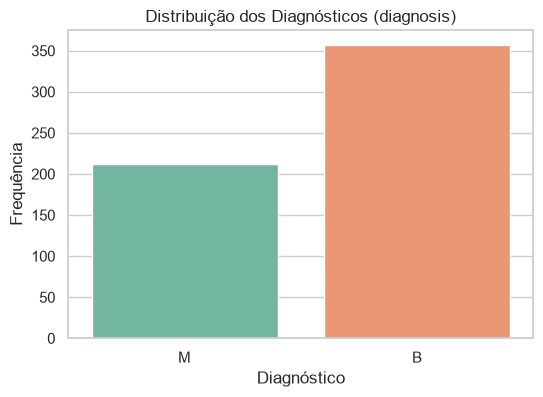

In [5]:
# Busca automática da coluna de diagnóstico/classe
colunas_possiveis = ['diagnosis', 'Class', 'target', 'outcome', 'Class_or_target']
coluna_alvo = [col for col in df.columns if col in colunas_possiveis or col.lower() in colunas_possiveis]

if coluna_alvo:
    alvo = coluna_alvo[0]
    print(f"--- DISTRIBUIÇÃO DA VARIÁVEL ALVO: '{alvo}' ---")
    print(df[alvo].value_counts(normalize=True) * 100)

    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=alvo, palette="Set2")
    plt.title(f"Distribuição dos Diagnósticos ({alvo})")
    plt.xlabel("Diagnóstico")
    plt.ylabel("Frequência")
    plt.show()

## 6. Análise de Correlação (Heatmap)

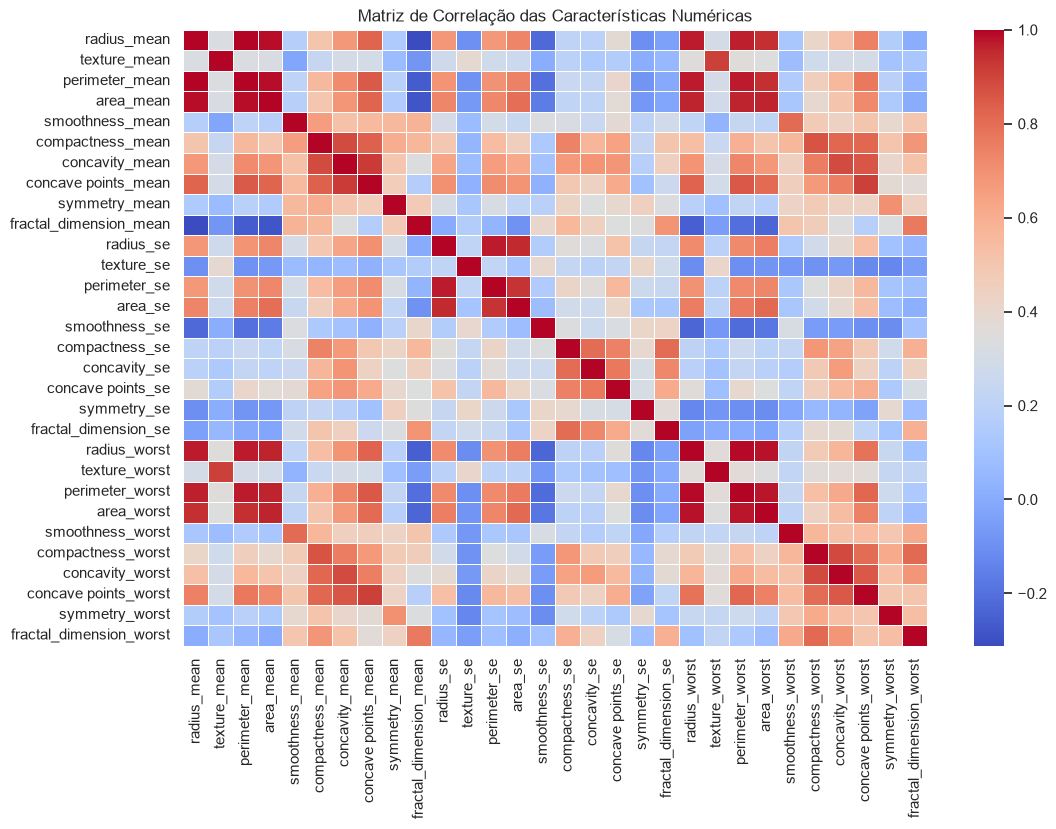

In [6]:
# Filtra variáveis numéricas e remove IDs não informativos se existirem
df_numeric = df.select_dtypes(include=[np.number])
colunas_para_remover = [col for col in ['id', 'Id', 'Sample_code_number', 'Unnamed: 32'] if col in df_numeric.columns]
df_numeric = df_numeric.drop(columns=colunas_para_remover)

plt.figure(figsize=(12, 8))
matriz_correlacao = df_numeric.corr()
sns.heatmap(matriz_correlacao, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Matriz de Correlação das Características Numéricas")
plt.show()

## 7. Distribuição das Principais Características

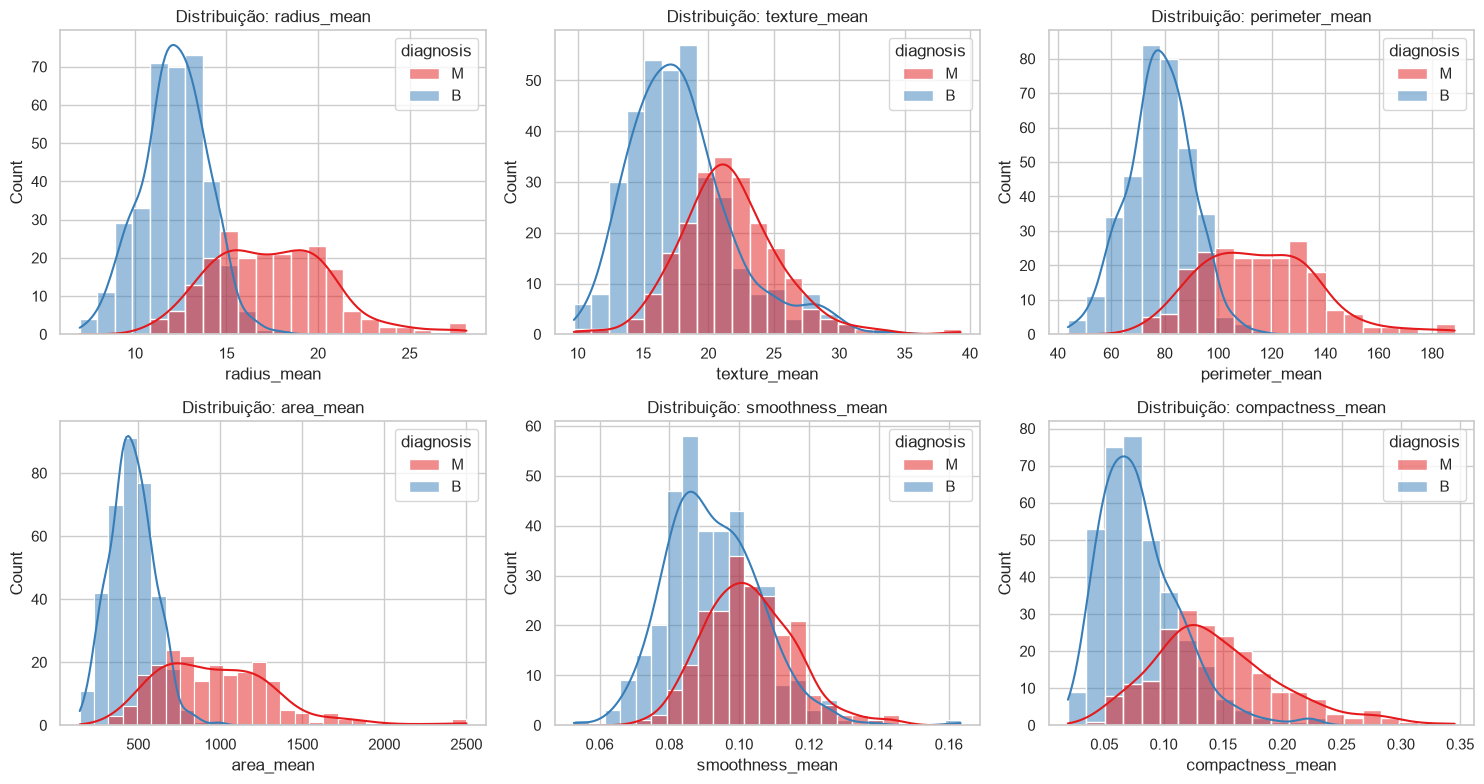

In [7]:
# Histogramas das 6 primeiras variáveis numéricas para avaliação de assimetria/outliers
colunas_grafico = [c for c in df_numeric.columns if c not in colunas_possiveis][:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(colunas_grafico):
    sns.histplot(data=df, x=col, hue=alvo if 'alvo' in locals() and alvo in df.columns else None, 
                 kde=True, ax=axes[i], palette="Set1")
    axes[i].set_title(f"Distribuição: {col}")

plt.tight_layout()
plt.show()